--- PRIMEIRAS LINHAS DO DATASET ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4



--- DISTRIBUIÇÃO DA NOVA CLASSE BINÁRIA (%) ---
target
0    86.089239
1    13.910761
Name: proportion, dtype: float64

--- RESUMO ESTATÍSTICO ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,target
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379,0.139108
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116,0.346210
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000,0.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000,0.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000,0.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000,1.000000


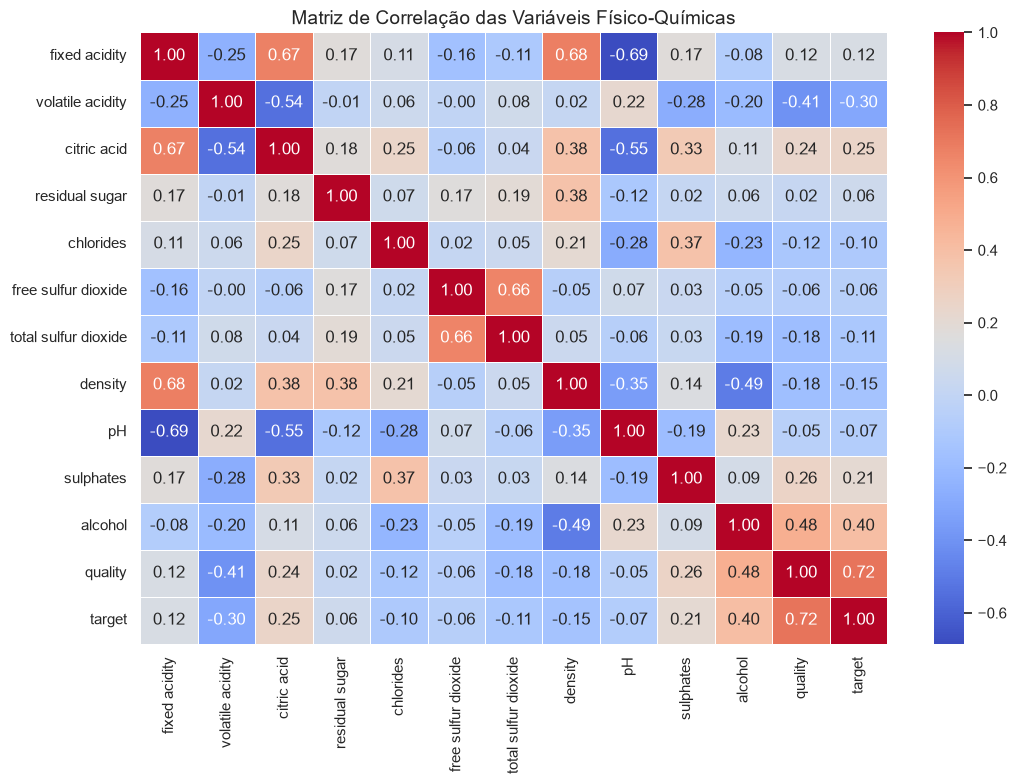

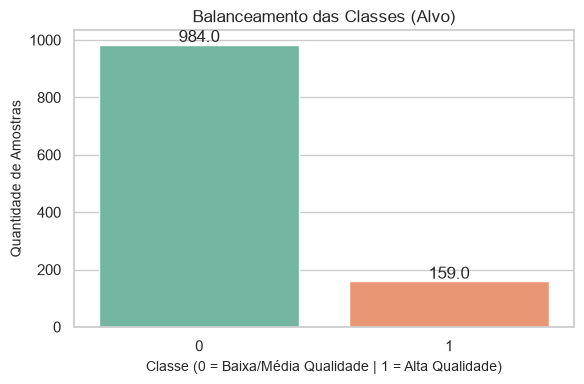

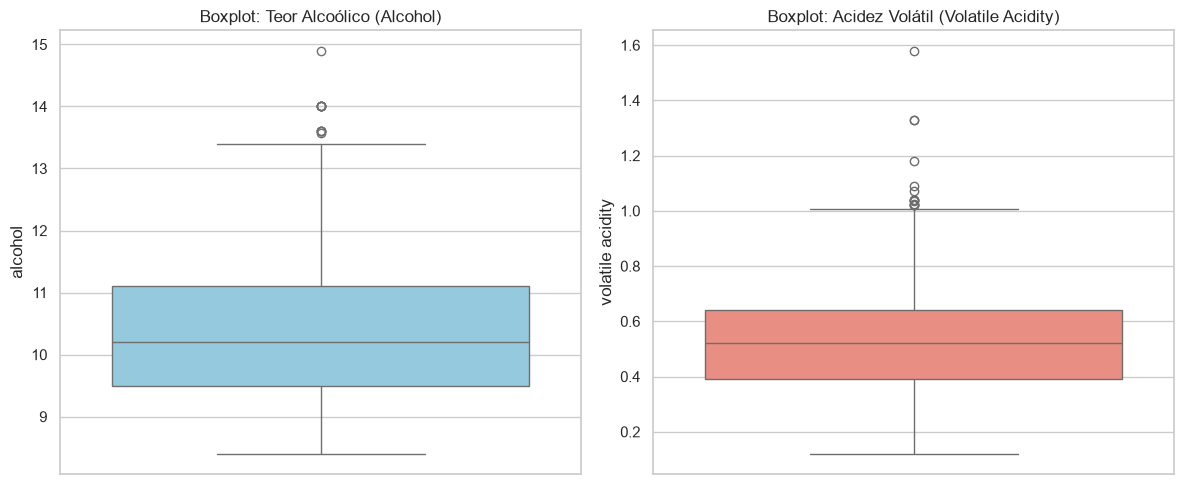

In [3]:
# 1. Importação das Bibliotecas Necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração para exibir os gráficos de forma limpa no notebook
%matplotlib inline
sns.set_theme(style="whitegrid")

# -------------------------------------------------------------
# ETAPA 1: COMPREENSÃO DO PROBLEMA E CARREGAMENTO DOS DADOS
# -------------------------------------------------------------

# Carregando a base de dados (ajuste o caminho se o seu arquivo estiver noutra pasta)
df = pd.read_csv('C:/Users/Aname/OneDrive/Desktop/Tech Challeng/Challeng 2/vinho-tech-challenge/WineQT.csv')

print("--- PRIMEIRAS LINHAS DO DATASET ---")
display(df.head())

# Transformação da variável de qualidade em classificação binária:
# Vinho de Alta Qualidade: nota >= 7 (1)
# Vinho de Baixa/Média Qualidade: nota < 7 (0)
df['target'] = np.where(df['quality'] >= 7, 1, 0)

print("\n--- DISTRIBUIÇÃO DA NOVA CLASSE BINÁRIA (%) ---")
class_distribution = df['target'].value_counts(normalize=True) * 100
print(class_distribution)


# -------------------------------------------------------------
# ETAPA 2: ANÁLISE EXPLORATÓRIA DE DADOS (EDA)
# -------------------------------------------------------------

# 1. Resumo estatístico para entender as distribuições básicas
print("\n--- RESUMO ESTATÍSTICO ---")
display(df.describe())

# 2. Investigação de Correlações (Mapa de Calor)
plt.figure(figsize=(11, 8))
# Removemos a coluna 'Id' se ela existir para não sujar a matriz de correlação
corr_matrix = df.drop(columns=['Id'], errors='ignore').corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlação das Variáveis Físico-Químicas", fontsize=14)
plt.tight_layout()
plt.show()

# 3. Análise do Balanceamento das Classes (Gráfico de Barras)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='target', hue='target', data=df, palette='Set2', legend=False)
plt.title("Balanceamento das Classes (Alvo)", fontsize=12)
plt.xlabel("Classe (0 = Baixa/Média Qualidade | 1 = Alta Qualidade)", fontsize=10)
plt.ylabel("Quantidade de Amostras", fontsize=10)
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# 4. Detecção de Outliers (Exemplo com o Teor Alcoólico e Acidez Volátil)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['alcohol'], color='skyblue')
plt.title("Boxplot: Teor Alcoólico (Alcohol)")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['volatile acidity'], color='salmon')
plt.title("Boxplot: Acidez Volátil (Volatile Acidity)")

plt.tight_layout()
plt.show()